# MultiUsvEnv 全面测试

本 Notebook 用于对 `MultiUsvEnv` 进行结构化、可复现的全面测试。

覆盖内容：
1. Seed 复现性
2. 观测/动作接口一致性
3. Active Mask 冻结机制
4. 输入参数校验
5. 全局目标状态同步
6. USV-USV 碰撞检测
7. USV-障碍物碰撞检测
8. 超步数终止条件
9. all_sequence_completed 终止条件
10. 随机短程压力测试

In [2]:
import os
import sys
import traceback
import numpy as np

# 将项目根目录加入导入路径（当前 notebook 位于 test/ 下）
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from my_USV_Env import MultiUsvEnv

print('导入成功:', MultiUsvEnv)

导入成功: <class 'my_USV_Env.MultiUsvEnv'>


In [3]:
# 测试工具函数
def assert_true(cond, msg):
    if not cond:
        raise AssertionError(msg)

def assert_allclose(a, b, msg, atol=1e-6):
    if not np.allclose(a, b, atol=atol):
        raise AssertionError(msg)

def allclose_nested_obs(obs_a, obs_b, atol=1e-6):
    if set(obs_a.keys()) != set(obs_b.keys()):
        return False
    for k in obs_a.keys():
        if set(obs_a[k].keys()) != set(obs_b[k].keys()):
            return False
        for sub_k in obs_a[k].keys():
            if not np.allclose(obs_a[k][sub_k], obs_b[k][sub_k], atol=atol):
                return False
    return True

print('测试工具加载完成')

测试工具加载完成


In [4]:
# 1) Seed 复现性
def test_seed_reproducibility():
    env_a = MultiUsvEnv(num_usvs=2, num_targets=6, num_obstacles=5, seed=2026, current_type='generated')
    obs_a = env_a.reset(seed=2026)
    starts_a = np.array(env_a.start_positions, dtype=np.float32)
    targets_a = np.array([[t.x, t.y] for t in env_a.targets], dtype=np.float32)

    env_b = MultiUsvEnv(num_usvs=2, num_targets=6, num_obstacles=5, seed=2026, current_type='generated')
    obs_b = env_b.reset(seed=2026)
    starts_b = np.array(env_b.start_positions, dtype=np.float32)
    targets_b = np.array([[t.x, t.y] for t in env_b.targets], dtype=np.float32)

    assert_allclose(starts_a, starts_b, '相同 seed 下起点不一致')
    assert_allclose(targets_a, targets_b, '相同 seed 下目标不一致')
    assert_true(allclose_nested_obs(obs_a, obs_b), '相同 seed 下初始观测不一致')


# 2) 观测/动作接口一致性
def test_observation_action_interfaces():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=3, seed=101, current_type='generated')
    obs = env.reset(seed=101)

    assert_true(set(obs.keys()) == {'usv_0', 'usv_1'}, '多USV观测主键不正确')
    for usv_k in ['usv_0', 'usv_1']:
        for sub_k in ['o_usv', 'targets', 'o_current', 'o_detector']:
            assert_true(sub_k in obs[usv_k], f'{usv_k} 缺少字段 {sub_k}')
            arr = obs[usv_k][sub_k]
            assert_true(np.all(np.isfinite(arr)), f'{usv_k}.{sub_k} 存在非有限值')

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    obs2, done2, crush2, truncated2, info2 = env.step(actions, goals)

    assert_true(isinstance(done2, (bool, np.bool_)), 'done 类型异常')
    assert_true(isinstance(crush2, (bool, np.bool_)), 'crush 类型异常')
    assert_true(isinstance(truncated2, (bool, np.bool_)), 'truncated 类型异常')
    assert_true('termination_reason' in info2, 'info 缺少 termination_reason')
    assert_true(obs2['usv_0']['o_usv'].shape[0] == 7, 'o_usv 维度应为 7')


# 3) Active Mask 冻结
def test_active_mask_freeze():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=3, seed=111, current_type='generated')
    _ = env.reset(seed=111)

    pre = np.array([[u.x, u.y] for u in env.usvs], dtype=np.float32)
    actions = np.array([[0.8, 0.0], [0.8, 0.0]], dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    mask = np.array([True, False], dtype=bool)

    _, _, _, _, _ = env.step(actions, goals, usv_active_mask=mask)
    post = np.array([[u.x, u.y] for u in env.usvs], dtype=np.float32)

    assert_true(not np.allclose(pre[0], post[0]), 'active=True 的 USV 位置未更新')
    assert_true(np.allclose(pre[1], post[1]), 'active=False 的 USV 位置发生变化')


# 4) 输入参数校验
def test_input_validation_errors():
    env = MultiUsvEnv(num_usvs=2, num_targets=3, num_obstacles=2, seed=12, current_type='generated')
    _ = env.reset(seed=12)

    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]

    bad_action_raised = False
    try:
        env.step(np.zeros((2, 3), dtype=np.float32), goals)
    except ValueError:
        bad_action_raised = True
    assert_true(bad_action_raised, '错误动作维度未触发 ValueError')

    bad_goal_raised = False
    try:
        env.step(np.zeros((2, 2), dtype=np.float32), goals[:1])
    except ValueError:
        bad_goal_raised = True
    assert_true(bad_goal_raised, '错误 goals 长度未触发 ValueError')


# 5) 全局目标状态同步
def test_global_target_status_sync():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=7,
        current_type='generated',
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])],
        fixed_targets=[np.array([30.0, 30.0]), np.array([70.0, 70.0])]
    )
    _ = env.reset(seed=7)

    env.usvs[0].x, env.usvs[0].y = 30.0, 30.0
    env.usvs[1].x, env.usvs[1].y = 70.0, 70.0
    env.usvs[0]._update_polygon()
    env.usvs[1]._update_polygon()
    env.current_positions = np.array([[30.0, 30.0], [70.0, 70.0]], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([30.0, 30.0], dtype=np.float32), np.array([70.0, 70.0], dtype=np.float32)]
    _, _, _, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(int(info['target_status'].sum()) == 2, '目标全局状态未正确更新')


# 6) USV-USV 碰撞检测
def test_usv_usv_collision_detection():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=77,
        current_type='generated',
        fixed_start_positions=[np.array([20.0, 20.0]), np.array([80.0, 80.0])]
    )
    _ = env.reset(seed=77)

    env.usvs[0].x, env.usvs[0].y = 50.0, 50.0
    env.usvs[1].x, env.usvs[1].y = 50.0, 50.0
    env.usvs[0]._update_polygon()
    env.usvs[1]._update_polygon()
    env.current_positions = np.array([[50.0, 50.0], [50.0, 50.0]], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([60.0, 60.0], dtype=np.float32), np.array([40.0, 40.0], dtype=np.float32)]
    _, done, crush, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(crush, '重叠构造下 crush 应为 True')
    assert_true(len(info['usv_collision_pairs']) > 0, '应检测到 usv_collision_pairs')
    assert_true(done, '碰撞时 done 应为 True')


# 7) USV-障碍物碰撞检测
def test_usv_obstacle_collision_detection():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=1,
        seed=41,
        current_type='generated',
        fixed_obstacles=[np.array([50.0, 50.0, 8.0])],
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])]
    )
    _ = env.reset(seed=41)

    env.usvs[0].x, env.usvs[0].y = 50.0, 50.0
    env.usvs[0]._update_polygon()
    env.current_positions[0] = np.array([50.0, 50.0], dtype=np.float32)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([80.0, 80.0], dtype=np.float32), np.array([20.0, 20.0], dtype=np.float32)]
    _, done, crush, _, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(crush, '障碍物重叠下 crush 应为 True')
    assert_true(any(info['obstacle_collisions']), '应检测到 obstacle_collisions')
    assert_true(done, '碰撞时 done 应为 True')


# 8) 超步数终止
def test_all_active_timeout_termination():
    env = MultiUsvEnv(
        num_usvs=2,
        num_targets=2,
        num_obstacles=0,
        seed=88,
        per_usv_max_steps=2,
        current_type='generated',
        fixed_start_positions=[np.array([10.0, 10.0]), np.array([90.0, 90.0])]
    )
    _ = env.reset(seed=88)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [np.array([95.0, 95.0], dtype=np.float32), np.array([5.0, 5.0], dtype=np.float32)]

    out = None
    for _ in range(3):
        out = env.step(actions, goals, usv_active_mask=np.array([True, True], dtype=bool))

    _, done, crush, truncated, info = out
    assert_true(done, '超步数后 done 应为 True')
    assert_true(truncated, '超步数后 truncated 应为 True')
    assert_true(not crush, '该构造场景不应碰撞')
    assert_true(info['termination_reason'] == 'all_active_timeout', '终止原因应为 all_active_timeout')


# 9) all_sequence_completed 终止
def test_all_sequence_completed_termination():
    env = MultiUsvEnv(num_usvs=2, num_targets=2, num_obstacles=0, seed=66, current_type='generated')
    _ = env.reset(seed=66)

    actions = np.zeros((2, 2), dtype=np.float32)
    goals = [
        np.array([env.targets[0].x, env.targets[0].y], dtype=np.float32),
        np.array([env.targets[1].x, env.targets[1].y], dtype=np.float32),
    ]
    _, done, crush, truncated, info = env.step(actions, goals, usv_active_mask=np.array([False, False], dtype=bool))

    assert_true(done, 'all_sequence_completed 下 done 应为 True')
    assert_true(not crush, 'all_sequence_completed 构造不应碰撞')
    assert_true(not truncated, 'all_sequence_completed 下 truncated 应为 False')
    assert_true(info['termination_reason'] == 'all_sequence_completed', '终止原因应为 all_sequence_completed')


# 10) 短程随机压力测试
def test_short_random_stress():
    env = MultiUsvEnv(num_usvs=2, num_targets=4, num_obstacles=4, seed=303, current_type='generated')
    obs = env.reset(seed=303)

    for step_i in range(80):
        actions = env.action_space.sample().astype(np.float32)
        goals = []
        for i in range(env.num_usvs):
            target_i = env.targets[i % env.num_targets]
            goals.append(np.array([target_i.x, target_i.y], dtype=np.float32))

        obs, done, crush, truncated, info = env.step(actions, goals, usv_active_mask=np.array([True, True], dtype=bool))

        assert_true(set(obs.keys()) == {'usv_0', 'usv_1'}, '压力测试中观测主键异常')
        for usv_k in ['usv_0', 'usv_1']:
            for sub_k in ['o_usv', 'targets', 'o_current', 'o_detector']:
                arr = obs[usv_k][sub_k]
                assert_true(np.all(np.isfinite(arr)), f'压力测试第{step_i}步 {usv_k}.{sub_k} 出现非有限值')

        if done:
            assert_true(info['termination_reason'] in ['collision', 'all_sequence_completed', 'all_active_timeout'], '未知终止原因')
            break


print('测试函数定义完成')

测试函数定义完成


In [10]:
# 运行全部测试并输出汇总
test_cases = [
    ('Seed 复现性', test_seed_reproducibility),
    ('观测/动作接口一致性', test_observation_action_interfaces),
    ('Active Mask 冻结', test_active_mask_freeze),
    ('输入参数校验', test_input_validation_errors),
    ('全局目标状态同步', test_global_target_status_sync),
    ('USV-USV 碰撞检测', test_usv_usv_collision_detection),
    ('USV-障碍物碰撞检测', test_usv_obstacle_collision_detection),
    ('超步数终止条件', test_all_active_timeout_termination),
    ('all_sequence_completed 终止条件', test_all_sequence_completed_termination),
    ('短程随机压力测试', test_short_random_stress),
]

results = []
for name, fn in test_cases:
    try:
        fn()
        print(f'[PASS] {name}')
        results.append((name, 'PASS', ''))
    except Exception as e:
        print(f'[FAIL] {name}: {e}')
        traceback.print_exc(limit=1)
        results.append((name, 'FAIL', str(e)))

pass_count = sum(1 for _, status, _ in results if status == 'PASS')
fail_count = len(results) - pass_count

print('\n' + '=' * 72)
print(f'测试总数: {len(results)} | 通过: {pass_count} | 失败: {fail_count}')
print('=' * 72)

if fail_count > 0:
    print('失败项:')
    for name, status, msg in results:
        if status == 'FAIL':
            print(f'  - {name}: {msg}')
else:
    print('所有 MultiUsvEnv 测试均通过。')

[PASS] Seed 复现性
[PASS] 观测/动作接口一致性
[FAIL] Active Mask 冻结: active=False 的 USV 位置发生变化


Traceback (most recent call last):
  File "C:\Windows\Temp\ipykernel_21696\2894604694.py", line 18, in <module>
    fn()
AssertionError: active=False 的 USV 位置发生变化


[PASS] 输入参数校验
[PASS] 全局目标状态同步
[PASS] USV-USV 碰撞检测
[PASS] USV-障碍物碰撞检测
[PASS] 超步数终止条件
[PASS] all_sequence_completed 终止条件
[PASS] 短程随机压力测试

测试总数: 10 | 通过: 9 | 失败: 1
失败项:
  - Active Mask 冻结: active=False 的 USV 位置发生变化


## 11. 多USV环境可视化

本节绘制多USV初始环境：
- 障碍物（不同形状）
- 目标点与目标半径
- 多艘USV起点与朝向

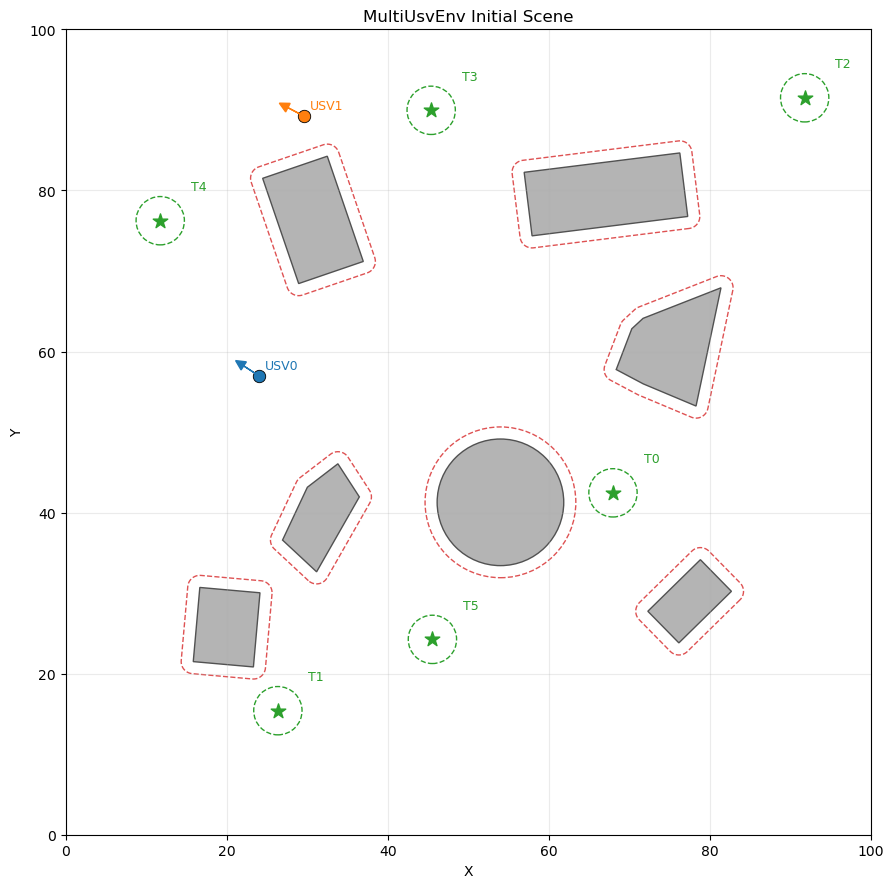

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon as MplPolygon


def plot_multi_usv_env(env, ax=None, title='MultiUsvEnv Scene'):
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 9))

    # 障碍物
    for obs in env.obstacles:
        shape = getattr(obs.shape, 'value', str(obs.shape))
        if shape == 'circle':
            ax.add_patch(Circle((obs.x, obs.y), obs.radius_o, facecolor='#B0B0B0', edgecolor='#4A4A4A', linewidth=1.0, alpha=0.95))
            ax.add_patch(Circle((obs.x, obs.y), obs.radius_o + obs.rou_c, facecolor='none', edgecolor='#D62728', linestyle='--', linewidth=1.0, alpha=0.8))
        else:
            verts = np.array(list(obs.geometry.exterior.coords)[:-1], dtype=np.float32)
            ax.add_patch(MplPolygon(verts, closed=True, facecolor='#B0B0B0', edgecolor='#4A4A4A', linewidth=1.0, alpha=0.95))
            danger_verts = np.array(list(obs.danger_zone.exterior.coords)[:-1], dtype=np.float32)
            ax.add_patch(MplPolygon(danger_verts, closed=True, facecolor='none', edgecolor='#D62728', linestyle='--', linewidth=1.0, alpha=0.8))

    # 目标
    for i, t in enumerate(env.targets):
        ax.add_patch(Circle((t.x, t.y), t.radius_t, facecolor='none', edgecolor='#2CA02C', linestyle='--', linewidth=1.0))
        ax.scatter(t.x, t.y, marker='*', s=120, c='#2CA02C', zorder=5)
        ax.text(t.x + t.radius_t + 0.8, t.y + t.radius_t + 0.8, f'T{i}', fontsize=9, color='#2CA02C')

    # USV 起点与朝向
    cmap = ['#1F77B4', '#FF7F0E', '#9467BD', '#17BECF', '#8C564B']
    for i, usv in enumerate(env.usvs):
        c = cmap[i % len(cmap)]
        ax.scatter(usv.x, usv.y, s=80, c=c, marker='o', edgecolors='black', linewidths=0.6, zorder=6)
        dx = 2.2 * np.cos(usv.heading)
        dy = 2.2 * np.sin(usv.heading)
        ax.arrow(usv.x, usv.y, dx, dy, head_width=1.2, head_length=1.2, fc=c, ec=c, linewidth=1.0, zorder=6)
        ax.text(usv.x + 0.8, usv.y + 0.8, f'USV{i}', fontsize=9, color=c)

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect('equal')
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_title(title)
    ax.grid(alpha=0.25)
    return ax


# 创建一个可视化场景
env_vis = MultiUsvEnv(
    num_usvs=2,
    num_targets=6,
    num_obstacles=7,
    seed=2026,
    current_type='generated'
)
_ = env_vis.reset(seed=2026)

fig, ax = plt.subplots(figsize=(9, 9))
plot_multi_usv_env(env_vis, ax=ax, title='MultiUsvEnv Initial Scene')
plt.tight_layout()
plt.show()

## 12. 多USV运动轨迹可视化

本节进行多USV仿真并绘制轨迹图（包含起点、终点、航迹与环境要素）。

已加载 actuator 参数: d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output\actuator_actor.pth
state_dim=26, goal_dim=2, action_dim=2


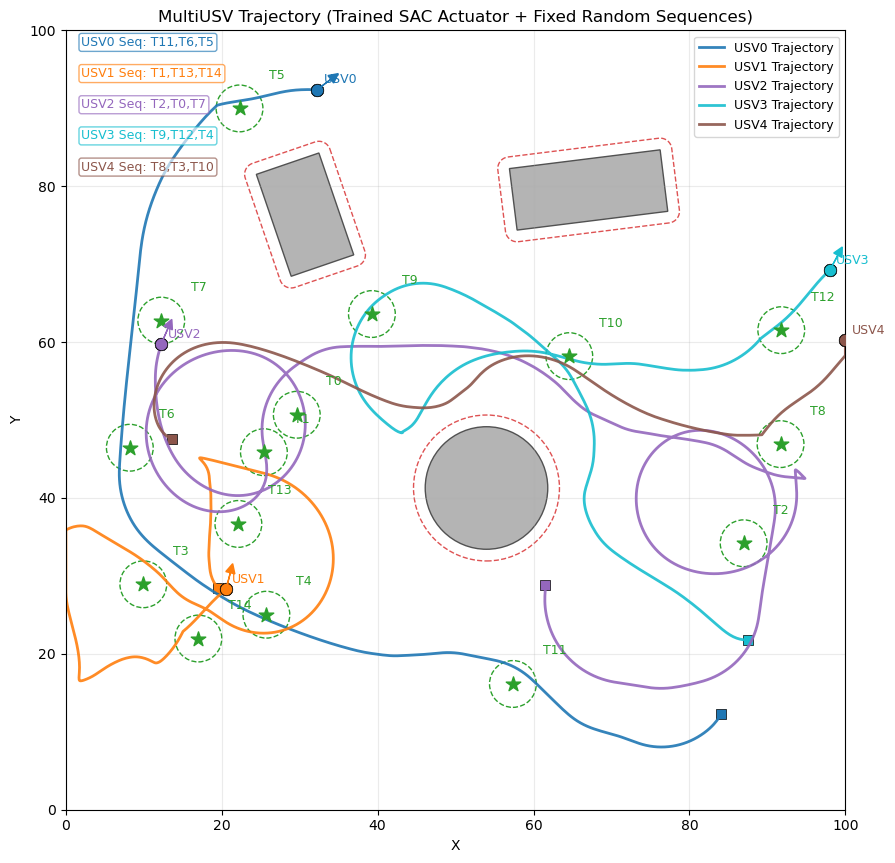

仿真步数: 646
终止原因: all_sequence_completed
已访问目标数: 15/15
USV碰撞对: []
障碍物碰撞标记: [False, False, False, False, False]
固定随机序列分配: [[11, 6, 5], [1, 13, 14], [2, 0, 7], [9, 12, 4], [8, 3, 10]]
各USV序列完成状态: [True, True, True, True, True]


In [12]:
import os
import torch
from sac_agent import SACActuatorAgent


# 使用 mpc_hrl_sac_output_310 下的 actuator 网络参数
MODEL_DIR = os.path.join(project_root, 'mpc_hrl_sac_output')
ACTOR_PATH = os.path.join(MODEL_DIR, 'actuator_actor.pth')
if not os.path.exists(ACTOR_PATH):
    ACTOR_PATH = os.path.join(MODEL_DIR, 'best_actuator_actor.pth')


def assign_target_sequences_once(env, rng):
    """仅初始化时随机分配一次目标序列，后续固定不变。"""
    perm = rng.permutation(env.num_targets).tolist()
    sequences = [[] for _ in range(env.num_usvs)]

    # 将随机打乱后的目标按轮转方式分给各 USV，确保每个目标仅归属一个 USV
    for k, tidx in enumerate(perm):
        sequences[k % env.num_usvs].append(int(tidx))

    return sequences


def build_goals_and_mask_from_sequences(env, sequences, seq_ptr):
    """根据固定序列和当前指针生成 goals 与 active_mask。"""
    goals = []
    active_mask = np.zeros(env.num_usvs, dtype=bool)

    for i in range(env.num_usvs):
        seq = sequences[i]
        ptr = seq_ptr[i]

        if ptr < len(seq):
            tidx = seq[ptr]
            t = env.targets[tidx]
            goals.append(np.array([t.x, t.y], dtype=np.float32))
            active_mask[i] = True
        else:
            usv = env.usvs[i]
            goals.append(np.array([usv.x, usv.y], dtype=np.float32))

    return goals, active_mask


def get_actuator_state_multi(single_usv_obs):
    """多USV观测中单艇 actuator 状态: o_usv(7)+o_detector+o_current(4)。"""
    return np.concatenate([
        single_usv_obs['o_usv'],
        single_usv_obs['o_detector'],
        single_usv_obs['o_current']
    ]).astype(np.float32)


def compute_actions_with_trained_actor(env, obs_multi, goals, actuator, active_mask):
    """使用训练好的 SAC actuator actor 产生动作。"""
    actions = np.zeros((env.num_usvs, 2), dtype=np.float32)
    for i in range(env.num_usvs):
        if not active_mask[i]:
            continue

        obs_i = obs_multi[f'usv_{i}']
        state_i = get_actuator_state_multi(obs_i)

        usv_pos_norm = obs_i['o_usv'][0:2]
        goal_abs = goals[i]
        goal_norm = np.array([goal_abs[0] / 100.0, goal_abs[1] / 100.0], dtype=np.float32)
        relative_goal = goal_norm - usv_pos_norm

        # evaluate=True: 确定性策略（用于可视化评估）
        action_i = actuator.select_action(state_i, relative_goal, evaluate=True)
        actions[i] = np.clip(action_i, -1.0, 1.0)

    return actions


# 创建仿真环境
env_traj = MultiUsvEnv(
    num_usvs=5,
    num_targets=15,
    num_obstacles=3,
    seed=2026,
    per_usv_max_steps=2000,
    current_type='generated'
)
obs_multi = env_traj.reset(seed=2026)

# 根据当前观测自动推断维度并构建 SAC actuator
state_dim = get_actuator_state_multi(obs_multi['usv_0']).shape[0]
goal_dim = 2
action_dim = 2
actuator = SACActuatorAgent(
    state_dim=state_dim,
    goal_dim=goal_dim,
    action_dim=action_dim,
    max_action=1.0
)

# 加载已训练 actor 参数
actor_state = torch.load(ACTOR_PATH, map_location='cpu')
actuator.actor.load_state_dict(actor_state)
actuator.actor.eval()

print(f'已加载 actuator 参数: {ACTOR_PATH}')
print(f'state_dim={state_dim}, goal_dim={goal_dim}, action_dim={action_dim}')

# 仅用于初始随机分配（固定种子便于复现）
rng = np.random.default_rng(2026)

# 一次性随机分配目标序列
sequences = assign_target_sequences_once(env_traj, rng)
seq_ptr = [0 for _ in range(env_traj.num_usvs)]

# 记录轨迹
max_steps = 2000
trajectories = [[] for _ in range(env_traj.num_usvs)]
for i in range(env_traj.num_usvs):
    trajectories[i].append(np.array([env_traj.usvs[i].x, env_traj.usvs[i].y], dtype=np.float32))

term_info = None

for step_i in range(max_steps):
    goals, active_mask = build_goals_and_mask_from_sequences(env_traj, sequences, seq_ptr)

    if not np.any(active_mask):
        term_info = {
            'termination_reason': 'all_sequence_completed',
            'target_status': env_traj.target_status.copy(),
            'usv_collision_pairs': [],
            'obstacle_collisions': [False] * env_traj.num_usvs
        }
        break

    actions = compute_actions_with_trained_actor(env_traj, obs_multi, goals, actuator, active_mask)

    obs_multi, done, crush, truncated, info = env_traj.step(
        actions,
        goals,
        usv_active_mask=active_mask
    )

    # 推进各 USV 的序列指针：当前目标被访问后转到下一个
    for i in range(env_traj.num_usvs):
        while seq_ptr[i] < len(sequences[i]):
            tidx = sequences[i][seq_ptr[i]]
            if info['target_status'][tidx] >= 0.5:
                seq_ptr[i] += 1
            else:
                break

    for i in range(env_traj.num_usvs):
        trajectories[i].append(np.array([env_traj.usvs[i].x, env_traj.usvs[i].y], dtype=np.float32))

    if done:
        term_info = info
        break

if term_info is None:
    term_info = info

# 绘图：环境 + 轨迹
fig, ax = plt.subplots(figsize=(9, 9))
plot_multi_usv_env(env_traj, ax=ax, title='MultiUSV Trajectory (Trained SAC Actuator + Fixed Random Sequences)')

cmap = ['#1F77B4', '#FF7F0E', '#9467BD', '#17BECF', '#8C564B']
for i in range(env_traj.num_usvs):
    traj = np.array(trajectories[i], dtype=np.float32)
    c = cmap[i % len(cmap)]
    ax.plot(traj[:, 0], traj[:, 1], color=c, linewidth=2.0, alpha=0.9, label=f'USV{i} Trajectory')
    ax.scatter(traj[0, 0], traj[0, 1], color=c, marker='s', s=55, edgecolors='black', linewidths=0.5)
    ax.scatter(traj[-1, 0], traj[-1, 1], color=c, marker='X', s=70, edgecolors='black', linewidths=0.5)

    seq_text = ','.join([f'T{t}' for t in sequences[i]]) if len(sequences[i]) > 0 else 'None'
    ax.text(2, 98 - i * 4, f'USV{i} Seq: {seq_text}', color=c, fontsize=9,
            bbox=dict(facecolor='white', alpha=0.65, edgecolor=c, boxstyle='round,pad=0.2'))

ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

# 统计输出
completed_per_usv = [seq_ptr[i] == len(sequences[i]) for i in range(env_traj.num_usvs)]
print(f"仿真步数: {len(trajectories[0]) - 1}")
print(f"终止原因: {term_info.get('termination_reason', 'running')}")
print(f"已访问目标数: {int(term_info['target_status'].sum())}/{env_traj.num_targets}")
print(f"USV碰撞对: {term_info.get('usv_collision_pairs', [])}")
print(f"障碍物碰撞标记: {term_info.get('obstacle_collisions', [])}")
print(f"固定随机序列分配: {sequences}")
print(f"各USV序列完成状态: {completed_per_usv}")

# SOM 全局目标调度测试

参考 Zhao et al. (2024) 双层决策框架:
- **上层**: SOM 自组织映射 → 将 M 个目标分配给 N 个 USV
- **下层**: 训练好的 SAC Actuator → 每个 USV 独立导航到各自目标序列
- **终止条件**: 全部完成 / 碰撞 / 超时

In [13]:
import os, sys
import importlib
import numpy as np

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)

import som_scheduler
importlib.reload(som_scheduler)
from som_scheduler import SOMScheduler

# ============ 测试 1: SOM 基础分配 ============
print("=" * 50)
print("测试 1: SOM 基础目标分配")
print("=" * 50)

usv_pos = np.array([
    [10.0, 10.0],
    [90.0, 10.0],
    [50.0, 90.0],
])
target_pos = np.array([
    [15.0, 20.0],   # T0: 靠近 USV0
    [20.0, 15.0],   # T1: 靠近 USV0
    [85.0, 20.0],   # T2: 靠近 USV1
    [80.0, 25.0],   # T3: 靠近 USV1
    [55.0, 85.0],   # T4: 靠近 USV2
    [45.0, 80.0],   # T5: 靠近 USV2
])

scheduler = SOMScheduler(num_iterations=300, seed=42)
sequences = scheduler.schedule(usv_pos, target_pos)

for i, seq in enumerate(sequences):
    coords = [f"T{j}({target_pos[j][0]:.0f},{target_pos[j][1]:.0f})" for j in seq]
    print(f"  USV {i} ({usv_pos[i][0]:.0f},{usv_pos[i][1]:.0f}): {' → '.join(coords)}")

# 验证: 每个目标恰好被分配一次
all_assigned = []
for seq in sequences:
    all_assigned.extend(seq)
assert sorted(all_assigned) == list(range(6)), "目标分配不完整!"
print("  ✓ 所有目标均被分配且无重复")

# 验证: 分配总路径长度合理
total_dist = 0
for i, seq in enumerate(sequences):
    prev = usv_pos[i]
    for j in seq:
        total_dist += np.linalg.norm(prev - target_pos[j])
        prev = target_pos[j]
print(f"  SOM 总路径长度: {total_dist:.1f}m")

# ============ 测试 2: 负载均衡 ============
print("\n" + "=" * 50)
print("测试 2: 带负载均衡的 SOM 分配")
print("=" * 50)

usv_pos2 = np.array([[50.0, 50.0], [90.0, 90.0]])
target_pos2 = np.array([
    [45.0, 45.0], [48.0, 52.0], [52.0, 48.0],
    [55.0, 55.0], [50.0, 60.0],
    [85.0, 85.0],
])

seq_basic = scheduler.schedule(usv_pos2, target_pos2)
print(f"  基础分配: USV0={len(seq_basic[0])}个, USV1={len(seq_basic[1])}个")

seq_balanced = scheduler.schedule_with_balance(usv_pos2, target_pos2, max_imbalance=1)
print(f"  均衡分配: USV0={len(seq_balanced[0])}个, USV1={len(seq_balanced[1])}个")

all_b = []
for s in seq_balanced:
    all_b.extend(s)
assert sorted(all_b) == list(range(6)), "均衡后目标丢失!"
print("  ✓ 均衡后所有目标仍在, 负载均衡有效")

# ============ 测试 3: 边界情况 ============
print("\n" + "=" * 50)
print("测试 3: 边界情况")
print("=" * 50)

seq_empty = scheduler.schedule(usv_pos, np.zeros((0, 2)))
assert all(len(s) == 0 for s in seq_empty), "无目标时应返回空序列"
print("  ✓ 无目标 → 空序列")

seq_single = scheduler.schedule(usv_pos, np.array([[15.0, 12.0]]))
total = sum(len(s) for s in seq_single)
assert total == 1, "单目标应只分配一次"
print(f"  ✓ 单目标分配给 USV {[i for i,s in enumerate(seq_single) if len(s)>0][0]}")

print("\n全部 SOM 调度测试通过 ✓")

测试 1: SOM 基础目标分配
  USV 0 (10,10): T0(15,20) → T1(20,15)
  USV 1 (90,10): T2(85,20) → T3(80,25)
  USV 2 (50,90): T4(55,85) → T5(45,80)
  ✓ 所有目标均被分配且无重复
  SOM 总路径长度: 54.8m

测试 2: 带负载均衡的 SOM 分配
  基础分配: USV0=5个, USV1=1个
  均衡分配: USV0=4个, USV1=2个
  ✓ 均衡后所有目标仍在, 负载均衡有效

测试 3: 边界情况
  ✓ 无目标 → 空序列
  ✓ 单目标分配给 USV 0

全部 SOM 调度测试通过 ✓


In [14]:
"""
测试: SOM + MultiUsvEnv 集成 (不加载模型, 使用随机动作验证框架完整性)
"""
import numpy as np
from my_USV_Env import MultiUsvEnv
from som_scheduler import SOMScheduler
from hrl_helpers import get_actuator_state

NUM_USVS = 3
NUM_TARGETS = 6
NUM_OBSTACLES = 3
SEED = 2026
MAX_STEPS = 100  # 短程测试

# 1. 创建环境
env = MultiUsvEnv(
    num_usvs=NUM_USVS,
    num_targets=NUM_TARGETS,
    num_obstacles=NUM_OBSTACLES,
    seed=SEED,
    per_usv_max_steps=MAX_STEPS,
    current_type="generated",
)
obs = env.reset(seed=SEED)

# 2. SOM 分配
usv_positions = np.array(env.start_positions, dtype=np.float64)
target_positions = np.array([[t.x, t.y] for t in env.targets], dtype=np.float64)

scheduler = SOMScheduler(num_iterations=200, seed=SEED)
sequences = scheduler.schedule_with_balance(usv_positions, target_positions, max_imbalance=2)

print("SOM 目标分配:")
for i, seq in enumerate(sequences):
    print(f"  USV {i} @ ({usv_positions[i][0]:.1f}, {usv_positions[i][1]:.1f}): "
          f"targets = {seq}")

# 3. 使用随机动作运行几步, 验证框架
seq_cursors = [0] * NUM_USVS
usv_active = [len(sequences[i]) > 0 for i in range(NUM_USVS)]

for step in range(MAX_STEPS):
    actions = np.random.uniform(-1, 1, (NUM_USVS, 2)).astype(np.float32)
    goal_positions = []
    active_mask = np.array(usv_active, dtype=bool)

    for i in range(NUM_USVS):
        if usv_active[i]:
            t_idx = sequences[i][seq_cursors[i]]
            goal_positions.append(target_positions[t_idx].astype(np.float32))
        else:
            goal_positions.append(np.array([env.usvs[i].x, env.usvs[i].y], dtype=np.float32))

    obs, done, crush, truncated, info = env.step(actions, goal_positions, usv_active_mask=active_mask)

    # 检查子目标到达
    for i in range(NUM_USVS):
        if not usv_active[i]:
            continue
        t_idx = sequences[i][seq_cursors[i]]
        dist = np.linalg.norm(info['usv_positions'][i] - target_positions[t_idx])
        if dist < env.target_radius:
            seq_cursors[i] += 1
            print(f"  Step {step+1}: USV {i} reached T{t_idx}")
            if seq_cursors[i] >= len(sequences[i]):
                usv_active[i] = False

    if done or not any(usv_active):
        print(f"\n终止于 step {step+1}, reason={info.get('termination_reason', 'all_completed')}")
        break

print(f"\n框架集成测试完成 ✓")
print(f"  每个 USV 的观测空间正确: {all(f'usv_{i}' in obs for i in range(NUM_USVS))}")
print(f"  Actuator 状态维度: {get_actuator_state(obs['usv_0']).shape[0]}")

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


SOM 目标分配:
  USV 0 @ (84.0, 12.3): targets = [4]
  USV 1 @ (19.6, 28.4): targets = [5, 3, 2, 0]
  USV 2 @ (61.5, 28.8): targets = [1]

终止于 step 100, reason=all_active_timeout

框架集成测试完成 ✓
  每个 USV 的观测空间正确: True
  Actuator 状态维度: 26


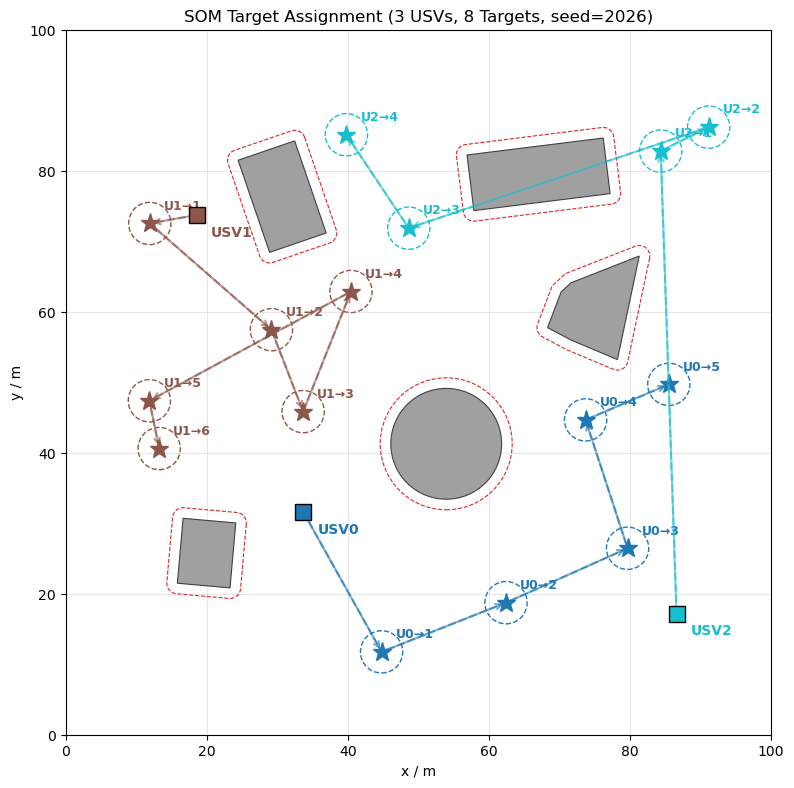


SOM 分配详情:
  USV 0: T3 → T12 → T8 → T11 → T7, 总路径长度 ≈ 92.6m
  USV 1: T9 → T1 → T13 → T4 → T10 → T0, 总路径长度 ≈ 99.9m
  USV 2: T5 → T6 → T2 → T14, 总路径长度 ≈ 134.1m


In [15]:
"""
可视化: SOM 目标分配结果
"""
import matplotlib.pyplot as plt
import numpy as np
from my_USV_Env import MultiUsvEnv
from som_scheduler import SOMScheduler

SEED = 2026

env = MultiUsvEnv(
    num_usvs=3, num_targets=15, num_obstacles=5,
    seed=SEED, current_type="generated",
)
env.reset(seed=SEED)

usv_pos = np.array(env.start_positions, dtype=np.float64)
target_pos = np.array([[t.x, t.y] for t in env.targets], dtype=np.float64)

scheduler = SOMScheduler(num_iterations=300, seed=SEED)
sequences = scheduler.schedule_with_balance(usv_pos, target_pos, max_imbalance=2)

# 绘图
fig, ax = plt.subplots(figsize=(8, 8))
colors = plt.cm.tab10(np.linspace(0, 1, 3))

# 障碍物
for obs in env.obstacles:
    obs.show_obstacle(ax)

# 目标 (按分配着色)
target_to_usv = {}
for i, seq in enumerate(sequences):
    for order, t_idx in enumerate(seq):
        target_to_usv[t_idx] = (i, order)

for j, t in enumerate(env.targets):
    if j in target_to_usv:
        usv_i, order = target_to_usv[j]
        c = colors[usv_i]
    else:
        c = 'gray'
    ax.add_patch(plt.Circle((t.x, t.y), t.radius_t,
                            facecolor='none', edgecolor=c, linestyle='--', linewidth=1))
    ax.plot(t.x, t.y, '*', color=c, markersize=14)
    if j in target_to_usv:
        usv_i, order = target_to_usv[j]
        ax.annotate(f"U{usv_i}→{order+1}", (t.x+2, t.y+2),
                    fontsize=9, color=c, fontweight='bold')

# USV 起点 + 序列连线
for i in range(3):
    c = colors[i]
    ax.plot(usv_pos[i][0], usv_pos[i][1], 's', color=c, markersize=12,
            markeredgecolor='black', zorder=8)
    ax.text(usv_pos[i][0]+2, usv_pos[i][1]-3, f"USV{i}",
            fontsize=10, color=c, fontweight='bold')

    # 绘制分配路径
    if sequences[i]:
        pts = [usv_pos[i]] + [target_pos[j] for j in sequences[i]]
        pts = np.array(pts)
        ax.plot(pts[:, 0], pts[:, 1], '--', color=c, linewidth=1.5, alpha=0.6)
        for k in range(1, len(pts)):
            dx = pts[k][0] - pts[k-1][0]
            dy = pts[k][1] - pts[k-1][1]
            ax.annotate("", xy=pts[k], xytext=pts[k-1],
                       arrowprops=dict(arrowstyle="->", color=c, lw=1.5, alpha=0.6))

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
ax.set_title(f"SOM Target Assignment (3 USVs, 8 Targets, seed={SEED})", fontsize=12)
ax.set_xlabel("x / m")
ax.set_ylabel("y / m")
plt.tight_layout()
plt.show()

print("\nSOM 分配详情:")
for i, seq in enumerate(sequences):
    names = [f"T{j}" for j in seq]
    total_dist = 0
    prev = usv_pos[i]
    for j in seq:
        total_dist += np.linalg.norm(prev - target_pos[j])
        prev = target_pos[j]
    print(f"  USV {i}: {' → '.join(names)}, 总路径长度 ≈ {total_dist:.1f}m")

# SOM + mpc_hrl_sac_output_310 Actuator 完整测试

使用 `mpc_hrl_sac_output_310` 下训练好的 SAC Actuator 网络作为 USV 控制策略，在 SOM 全局目标分配下运行多 USV 协同导航任务。

In [16]:
"""
SOM + mpc_hrl_sac_output_310 Actuator 多USV协同导航测试
"""
import importlib
import multi_usv_som_runner
importlib.reload(multi_usv_som_runner)
from multi_usv_som_runner import run_som_multi_usv, visualize_result

MODEL_DIR = os.path.join(project_root, "mpc_hrl_sac_output_310")

result = run_som_multi_usv(
    num_usvs=3,
    num_targets=15,
    num_obstacles=5,
    model_dir=MODEL_DIR,
    seed=2026,
    max_steps=4000,
    per_usv_max_steps=3000,
    som_iterations=300,
    som_balance=True,
    max_imbalance=2,
    target_radius=3.0,
    verbose=True,
)


Multi-USV SOM Navigation
  USVs: 3, Targets: 15, Obstacles: 5
  Seed: 2026, Max steps: 4000

Loading actuator from: d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310
  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_actor.pth
  Loaded critic from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_critic.pth

SOM Target Assignment:
  USV 0: T3(44.8,11.8) → T12(62.4,18.7) → T8(79.7,26.5) → T11(73.7,44.7) → T7(85.5,49.7)
  USV 1: T9(11.9,72.5) → T1(29.2,57.5) → T13(33.7,45.8) → T4(40.4,62.9) → T10(11.8,47.4) → T0(13.2,40.6)
  USV 2: T5(84.4,82.8) → T6(91.2,86.2) → T2(48.6,71.9) → T14(39.8,85.1)
  Step 152: USV 0 reached target T3 (1/5)
  Step 196: USV 0 reached target T12 (2/5)
  Step 239: USV 0 reached target T8 (3/5)
  Step 251: USV 2 reached target T5 (1/4)
  Step 319: USV 0 reached target T11 (4/5)
  Step 432: USV 0 reached target T7 (5/5)
  ★ USV 0 completed all assigned targets!
  S

Figure saved to d:\fileForWhile\USV-MuilTarget-path-plaaning\som_mpc310_result.png


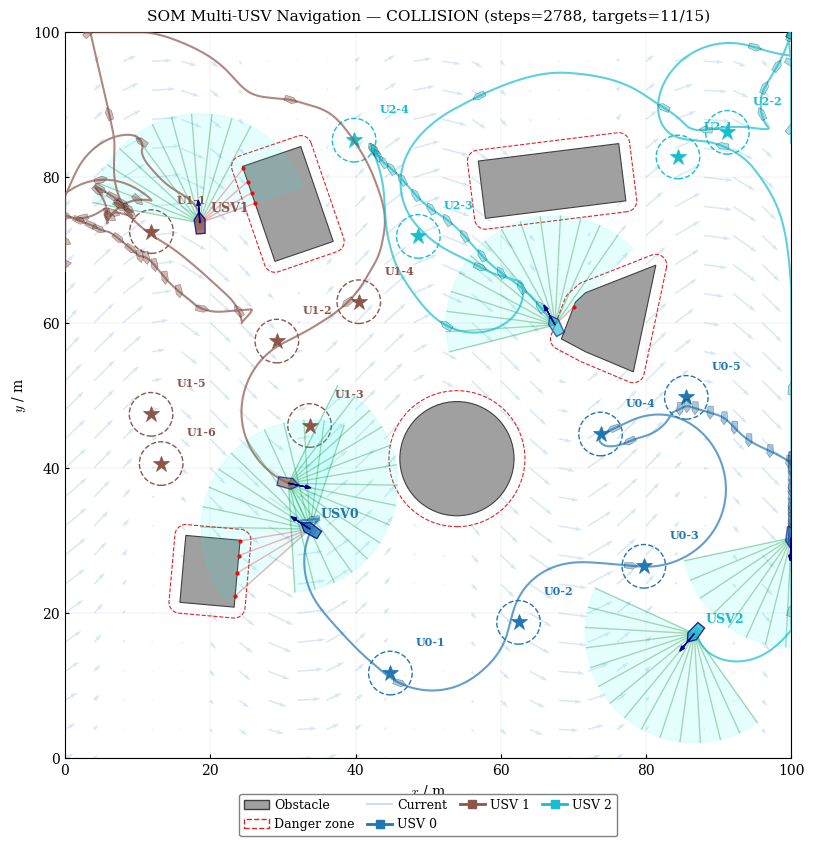

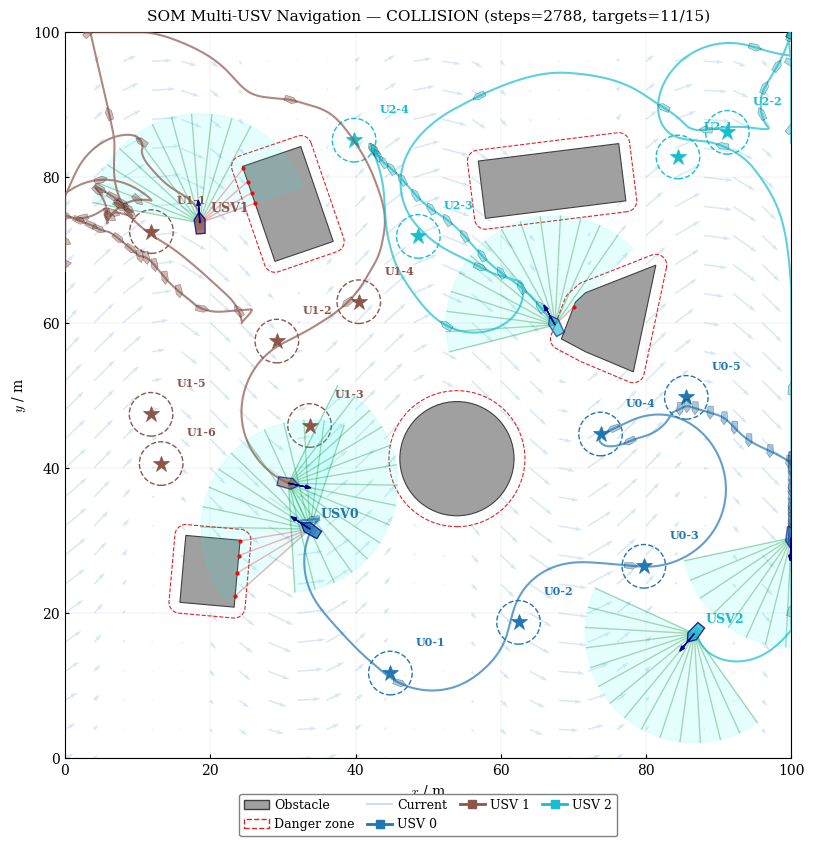

In [17]:
# 可视化导航结果
visualize_result(result, save_path=os.path.join(project_root, "som_mpc310_result.png"))

In [18]:
"""
多 Seed 批量测试: 评估 mpc_hrl_sac_output_310 在 SOM 调度下的统计表现
"""
import time

seeds = [2026, 42, 100, 123, 200, 303, 404, 555, 666, 888]
results_table = []

t0 = time.time()
for s in seeds:
    r = run_som_multi_usv(
        num_usvs=3,
        num_targets=6,
        num_obstacles=5,
        model_dir=MODEL_DIR,
        seed=s,
        max_steps=4000,
        per_usv_max_steps=3000,
        som_iterations=300,
        som_balance=True,
        target_radius=3.0,
        verbose=False,
    )
    results_table.append({
        'seed': s,
        'success': r['success'],
        'reason': r['termination_reason'],
        'steps': r['total_steps'],
        'reached': r['total_reached'],
        'total': r['total_assigned'],
        'rate': r['completion_rate'],
    })
    status = "✓" if r['success'] else "✖"
    print(f"  Seed {s:4d}: {status} {r['termination_reason']:25s} "
          f"steps={r['total_steps']:5d}  targets={r['total_reached']}/{r['total_assigned']} "
          f"({r['completion_rate']*100:5.1f}%)")

elapsed = time.time() - t0

# 汇总统计
n = len(results_table)
successes = sum(1 for r in results_table if r['success'])
avg_steps = np.mean([r['steps'] for r in results_table if r['success']]) if successes > 0 else float('nan')
avg_rate = np.mean([r['rate'] for r in results_table])
collision_count = sum(1 for r in results_table if 'collision' in r['reason'])
timeout_count = sum(1 for r in results_table if 'timeout' in r['reason'] or 'exceeded' in r['reason'])

print(f"\n{'='*60}")
print(f"mpc_hrl_sac_output_310 + SOM 统计结果 ({n} seeds)")
print(f"{'='*60}")
print(f"  成功率:       {successes}/{n} ({successes/n*100:.1f}%)")
print(f"  平均完成率:   {avg_rate*100:.1f}%")
print(f"  平均成功步数: {avg_steps:.0f}" if not np.isnan(avg_steps) else "  平均成功步数: N/A")
print(f"  碰撞终止:     {collision_count}/{n}")
print(f"  超时终止:     {timeout_count}/{n}")
print(f"  总耗时:       {elapsed:.1f}s")
print(f"{'='*60}")

  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_actor.pth
  Loaded critic from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_critic.pth
  Seed 2026: ✓ all_completed             steps=  688  targets=6/6 (100.0%)
  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_actor.pth
  Loaded critic from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_critic.pth
  Seed   42: ✖ collision                 steps= 2090  targets=5/6 ( 83.3%)
  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_actor.pth
  Loaded critic from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_critic.pth
  Seed  100: ✖ collision                 steps= 1856  targets=5/6 ( 83.3%)
  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actu

In [19]:
# 查看批量测试结果
print(f"成功率: {successes}/{n} ({successes/n*100:.1f}%)")
print(f"平均完成率: {avg_rate*100:.1f}%")
print(f"碰撞终止: {collision_count}/{n}, 超时终止: {timeout_count}/{n}")
print(f"耗时: {elapsed:.1f}s")
print()
for r in results_table:
    st = "✓" if r['success'] else "✖"
    print(f"  Seed {r['seed']:4d}: {st} {r['reason']:25s} steps={r['steps']:5d} targets={r['reached']}/{r['total']} ({r['rate']*100:.0f}%)")

成功率: 6/10 (60.0%)
平均完成率: 93.3%
碰撞终止: 4/10, 超时终止: 0/10
耗时: 79.5s

  Seed 2026: ✓ all_completed             steps=  688 targets=6/6 (100%)
  Seed   42: ✖ collision                 steps= 2090 targets=5/6 (83%)
  Seed  100: ✖ collision                 steps= 1856 targets=5/6 (83%)
  Seed  123: ✓ all_completed             steps= 1451 targets=6/6 (100%)
  Seed  200: ✓ all_completed             steps=  729 targets=6/6 (100%)
  Seed  303: ✖ collision                 steps=  820 targets=5/6 (83%)
  Seed  404: ✓ all_completed             steps=  585 targets=6/6 (100%)
  Seed  555: ✓ all_completed             steps=  434 targets=6/6 (100%)
  Seed  666: ✖ collision                 steps= 2799 targets=5/6 (83%)
  Seed  888: ✓ all_completed             steps= 1216 targets=6/6 (100%)


## SOM + Actuator网络


In [20]:
import importlib
import multi_usv_som_runner
importlib.reload(multi_usv_som_runner)
from multi_usv_som_runner import run_som_multi_usv, visualize_result, animate_result

# 运行导航任务（记录航向和传感器数据）
result = run_som_multi_usv(
    num_usvs=3,
    num_targets=10,
    num_obstacles=5,
    model_dir=MODEL_DIR,
    seed=2026,
    max_steps=3000,
    verbose=True,
)
print(f"\nheadings recorded: {[len(h) for h in result['headings']]}")
print(f"sensor_data recorded: {[len(s) for s in result['sensor_data']]}")


Multi-USV SOM Navigation
  USVs: 3, Targets: 10, Obstacles: 5
  Seed: 2026, Max steps: 3000

Loading actuator from: d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310
  Loaded actor from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_actor.pth
  Loaded critic from d:\fileForWhile\USV-MuilTarget-path-plaaning\mpc_hrl_sac_output_310\best_actuator_critic.pth

SOM Target Assignment:
  USV 0: T0(13.2,40.6) → T3(44.8,11.8)
  USV 1: T9(11.9,72.5) → T1(29.2,57.5) → T4(40.4,62.9) → T2(48.6,71.9)
  USV 2: T8(79.7,26.5) → T7(85.5,49.7) → T5(84.4,82.8) → T6(91.2,86.2)
  Step 59: USV 0 reached target T0 (1/2)
  Step 194: USV 0 reached target T3 (2/2)
  ★ USV 0 completed all assigned targets!
  Step 589: USV 2 reached target T8 (1/4)
  Step 748: USV 2 reached target T7 (2/4)
  Step 831: USV 2 reached target T5 (3/4)

  Environment terminated: all_active_timeout at step 2000

Result Summary:
  Success: False
  Termination: all_active_timeout
  Step

Figure saved to som_mpc310_usv_shape.png


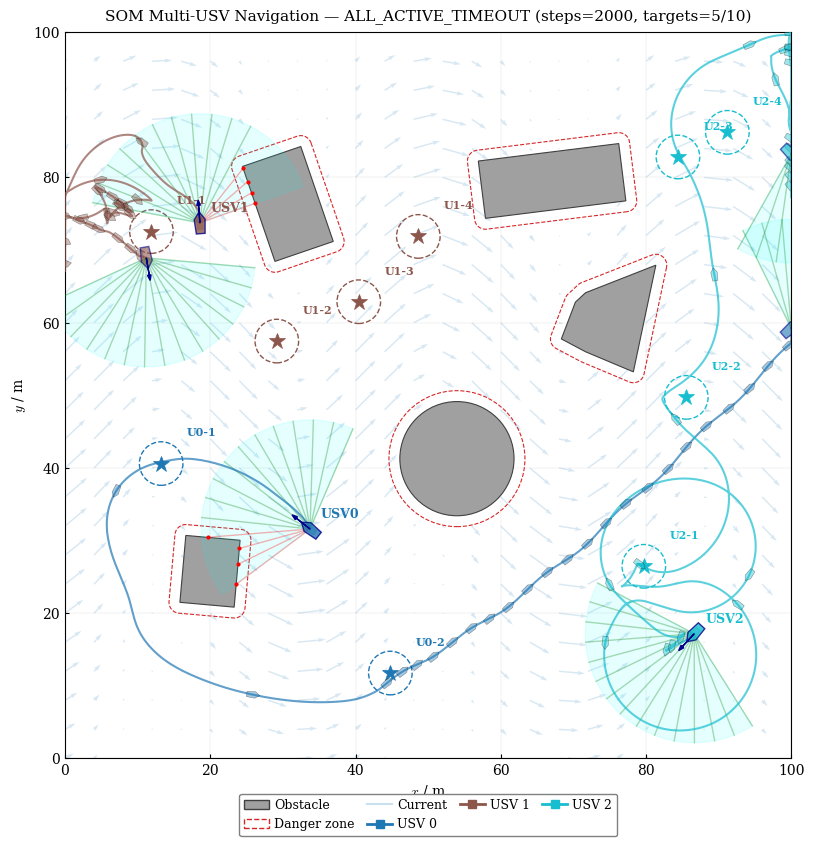

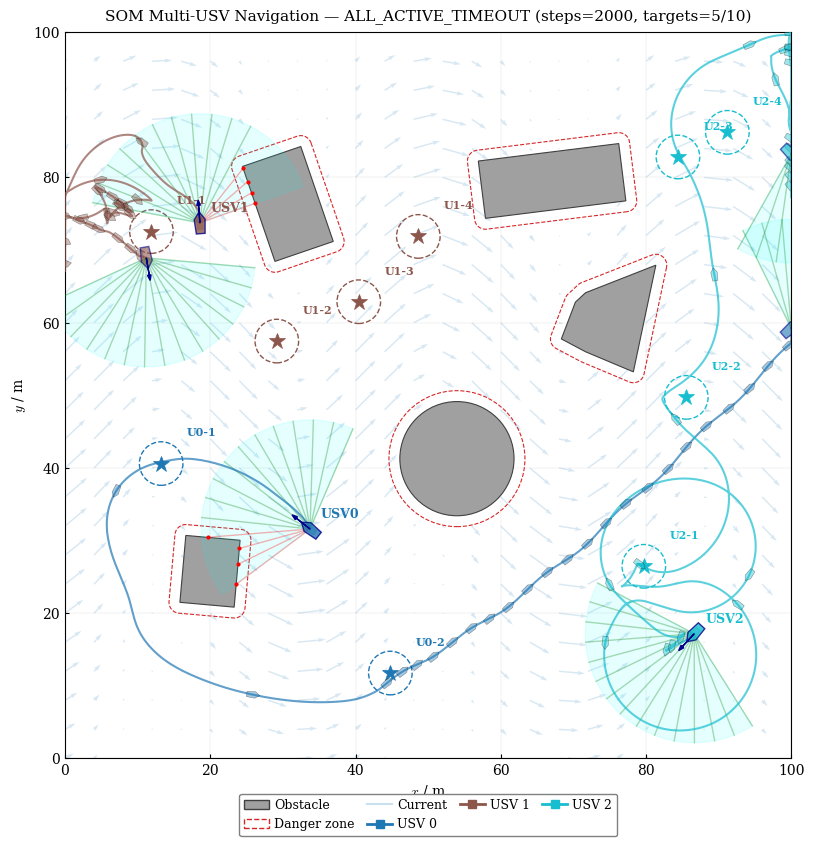

In [21]:
# 静态可视化：USV船体形状 + 传感器（起点/终点全尺寸，路径上间隔缩小版）
visualize_result(result, save_path="som_mpc310_usv_shape.png",
                 show_usv_shape=True, usv_interval=80, show_sensor=True)

In [22]:
# 动态可视化：多USV协同导航动画（USV形状 + 传感器 + 尾迹 + 时变海流）
animate_result(result, save_path="som_mpc310_animation.gif",
               interval=50, speed=8, trail_length=0, show_sensor=True)

Animation saved to som_mpc310_animation.gif  (250 frames)


# SOM + ReactiveController 完整测试

使用 SOM 全局目标调度 + ReactiveController（比例导航 + 反应式避障）作为底层控制器，验证多 USV 协同导航。

- **无需训练模型**：ReactiveController 为纯规则控制器
- 与 SAC Actuator 方案共享相同的 `visualize_result` / `animate_result` 可视化接口
- 适合作为 baseline 对比

In [5]:
"""
SOM + ReactiveController 单场景导航测试
"""
import importlib
import multi_usv_som_runner
importlib.reload(multi_usv_som_runner)
from multi_usv_som_runner import run_som_multi_usv_reactive, visualize_result, animate_result

result_reactive = run_som_multi_usv_reactive(
    num_usvs=3,
    num_targets=10,
    num_obstacles=5,
    seed=2026,
    max_steps=4000,
    per_usv_max_steps=3000,
    som_iterations=300,
    som_balance=True,
    max_imbalance=2,
    target_radius=3.0,
    verbose=True,
)

d:\Anaconda\anaconda3\envs\RL\lib\site-packages\gymnasium\spaces\box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")



Multi-USV SOM Navigation (Reactive Controller)
  USVs: 3, Targets: 10, Obstacles: 5
  Seed: 2026, Max steps: 4000

  ReactiveController created (kp_heading=2.0, max_throttle=0.04)

SOM Target Assignment:
  USV 0: T3(44.8,11.8) → T8(79.7,26.5)
  USV 1: T9(11.9,72.5) → T1(29.2,57.5) → T4(40.4,62.9) → T2(48.6,71.9) → T0(13.2,40.6)
  USV 2: T7(85.5,49.7) → T5(84.4,82.8) → T6(91.2,86.2)
  Step 283: USV 2 reached target T7 (1/3)
  Step 347: USV 0 reached target T3 (1/2)
  Step 373: USV 1 reached target T9 (1/5)
  Step 472: USV 2 reached target T5 (2/3)
  Step 576: USV 0 reached target T8 (2/2)
  ★ USV 0 completed all assigned targets!
  Step 586: USV 1 reached target T1 (2/5)
  Step 875: USV 1 reached target T4 (3/5)
  Step 1012: USV 1 reached target T2 (4/5)
  Step 1232: USV 2 reached target T6 (3/3)
  ★ USV 2 completed all assigned targets!
  Step 1313: USV 1 reached target T0 (5/5)
  ★ USV 1 completed all assigned targets!

  ★ All USVs completed their target sequences at step 1313!

Res

Figure saved to d:\fileForWhile\USV-MuilTarget-path-plaaning\som_reactive_result.png


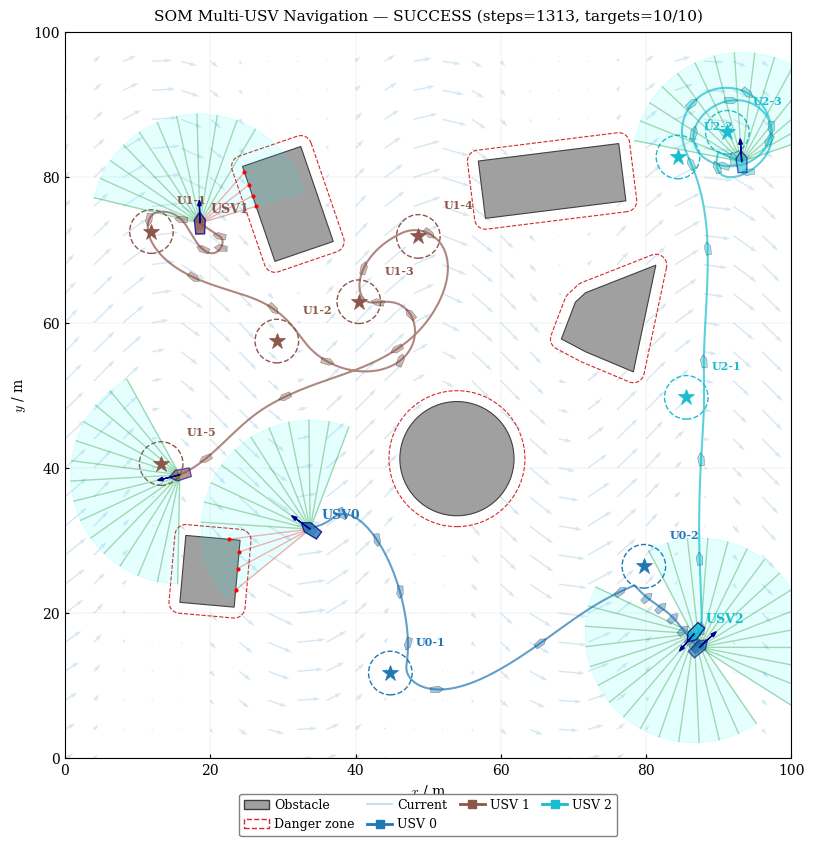

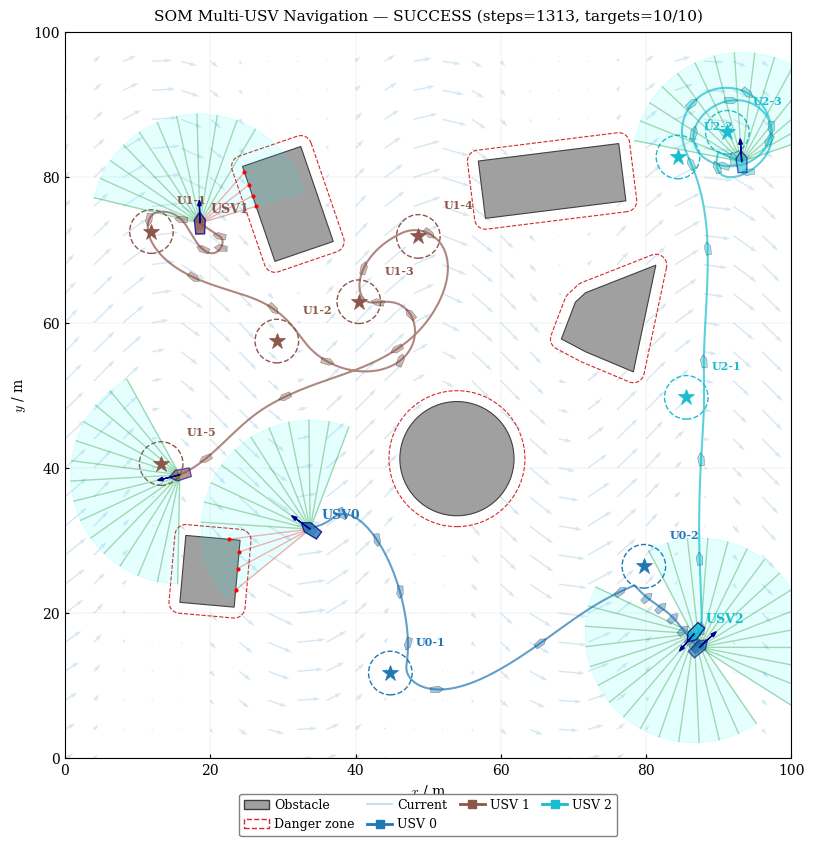

In [15]:
# 静态可视化: ReactiveController 导航轨迹
visualize_result(result_reactive, save_path=os.path.join(project_root, "som_reactive_result.png"),
                 show_usv_shape=True, usv_interval=80, show_sensor=True)

In [16]:
# 动态可视化: ReactiveController 导航动画
animate_result(result_reactive, save_path="som_reactive_animation.gif",
               interval=50, speed=8, trail_length=0, show_sensor=True)

Animation saved to som_reactive_animation.gif  (165 frames)


In [7]:
"""
多 Seed 批量测试: ReactiveController 在 SOM 调度下的统计表现
"""
import time

seeds_reactive = [2026, 42, 100, 123, 200, 303, 404, 555, 666, 888]
results_reactive = []

t0 = time.time()
for s in seeds_reactive:
    r = run_som_multi_usv_reactive(
        num_usvs=3,
        num_targets=10,
        num_obstacles=5,
        seed=s,
        max_steps=4000,
        per_usv_max_steps=3000,
        som_iterations=300,
        som_balance=True,
        target_radius=3.0,
        verbose=False,
    )
    results_reactive.append({
        'seed': s,
        'success': r['success'],
        'reason': r['termination_reason'],
        'steps': r['total_steps'],
        'reached': r['total_reached'],
        'total': r['total_assigned'],
        'rate': r['completion_rate'],
    })
    status = "✓" if r['success'] else "✖"
    print(f"  Seed {s:4d}: {status} {r['termination_reason']:25s} "
          f"steps={r['total_steps']:5d}  targets={r['total_reached']}/{r['total_assigned']} "
          f"({r['completion_rate']*100:5.1f}%)")

elapsed_reactive = time.time() - t0

# 汇总统计
n_r = len(results_reactive)
successes_r = sum(1 for r in results_reactive if r['success'])
avg_steps_r = np.mean([r['steps'] for r in results_reactive if r['success']]) if successes_r > 0 else float('nan')
avg_rate_r = np.mean([r['rate'] for r in results_reactive])
collision_r = sum(1 for r in results_reactive if 'collision' in r['reason'])
timeout_r = sum(1 for r in results_reactive if 'timeout' in r['reason'] or 'exceeded' in r['reason'])

print(f"\n{'='*60}")
print(f"ReactiveController + SOM 统计结果 ({n_r} seeds)")
print(f"{'='*60}")
print(f"  成功率:       {successes_r}/{n_r} ({successes_r/n_r*100:.1f}%)")
print(f"  平均完成率:   {avg_rate_r*100:.1f}%")
print(f"  平均成功步数: {avg_steps_r:.0f}" if not np.isnan(avg_steps_r) else "  平均成功步数: N/A")
print(f"  碰撞终止:     {collision_r}/{n_r}")
print(f"  超时终止:     {timeout_r}/{n_r}")
print(f"  总耗时:       {elapsed_reactive:.1f}s")
print(f"{'='*60}")

  Seed 2026: ✓ all_completed             steps= 1313  targets=10/10 (100.0%)
  Seed   42: ✖ collision                 steps=   85  targets=1/10 ( 10.0%)
  Seed  100: ✖ collision                 steps=  546  targets=5/10 ( 50.0%)
  Seed  123: ✖ collision                 steps=  144  targets=0/10 (  0.0%)
  Seed  200: ✖ collision                 steps=  833  targets=6/10 ( 60.0%)
  Seed  303: ✖ collision                 steps=  146  targets=0/10 (  0.0%)
  Seed  404: ✖ collision                 steps=  297  targets=2/10 ( 20.0%)
  Seed  555: ✖ collision                 steps=  681  targets=7/10 ( 70.0%)
  Seed  666: ✖ collision                 steps=  399  targets=3/10 ( 30.0%)
  Seed  888: ✓ all_completed             steps= 1682  targets=10/10 (100.0%)

ReactiveController + SOM 统计结果 (10 seeds)
  成功率:       2/10 (20.0%)
  平均完成率:   44.0%
  平均成功步数: 1498
  碰撞终止:     8/10
  超时终止:     0/10
  总耗时:       29.1s


In [ ]:
# 查看 ReactiveController 批量测试详情
print(f"成功率: {successes_r}/{n_r} ({successes_r/n_r*100:.1f}%)")
print(f"平均完成率: {avg_rate_r*100:.1f}%")
print(f"碰撞终止: {collision_r}/{n_r}, 超时终止: {timeout_r}/{n_r}")
print(f"耗时: {elapsed_reactive:.1f}s")
print()
for r in results_reactive:
    st = "✓" if r['success'] else "✖"
    print(f"  Seed {r['seed']:4d}: {st} {r['reason']:25s} steps={r['steps']:5d} targets={r['reached']}/{r['total']} ({r['rate']*100:.0f}%)")